# Search policy ablation, five-fold CV — greedy vs. archive

Run 2026-08-14. GRU seed (44.207), 120 evaluations per arm, **selection policy is the
only variable**. Scoring is 5-fold rolling-origin CV: 75 windows, mean over folds.

Schema note: the agents extended `results.tsv` to 8 columns —
`id, parent_id, competition_score, fold_std, fold_scores, eval_seconds, status, description`.
The per-fold breakdown is new and worth using: it separates a change that helped
everywhere from one that only helped on a single period.

Reads from the archived run directory, not the worktrees — those were removed after
both champions were verified to score `43.101` (greedy) and `43.143` (archive) from
the snapshot alone. Requires `export SDWPF_FOLDS_ROOT=.../evaluation/splits_rolling_5x30`.

In [2]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

WS   = Path.home() / "srip/windevolve_sdwpf/runs/search_policy_cv__aug14"
ROOT = Path.home() / "srip/windevolve_sdwpf"
FIGS = ROOT / "runs/search_policy_cv__aug14/figs"
FIGS.mkdir(parents=True, exist_ok=True)

ARMS     = {"greedy": "greedy-cv", "archive": "archive-cv"}
COL      = {"greedy": "tab:red", "archive": "tab:blue"}
INVALID  = 999.0
SEED     = 44.20662211508913
CAPACITY = 134.0                 # farm nameplate, for error-as-%-of-capacity
FOLDS    = ["F1", "F2", "F3", "F4", "F5"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.transparent": True,
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})

def load(arm_dir):
    df = pd.read_csv(WS / arm_dir / "results.tsv", sep="\t",
                     dtype={"id": str, "parent_id": str})
    df["n"]     = np.arange(1, len(df) + 1)
    df["valid"] = df.competition_score < INVALID
    df["score"] = df.competition_score.where(df.valid)
    df["best"]  = df.score.cummin().ffill()
    # explode the comma-separated per-fold scores into F1..F5 columns
    fs = df.fold_scores.astype(str).str.split(",", expand=True)
    for i, f in enumerate(FOLDS):
        df[f] = pd.to_numeric(fs[i], errors="coerce") if i < fs.shape[1] else np.nan
    return df

import os
# Set this before importing torch if the GPU is busy with someone else's job.
# os.environ["CUDA_VISIBLE_DEVICES"] = ""

if not os.environ.get("SDWPF_FOLDS_ROOT"):
    os.environ["SDWPF_FOLDS_ROOT"] = str(ROOT / "evaluation/splits_rolling_5x30")
print("folds root:", os.environ["SDWPF_FOLDS_ROOT"])

runs = {k: load(v) for k, v in ARMS.items()}
for k, df in runs.items():
    print(f"{k:8s} {len(df):3d} rows | {df.valid.sum():3d} scored | "
          f"best {df.best.iloc[-1]:.4f} MW | seed {df.score.iloc[0]:.4f}")

VERIFIED = {"greedy": 43.101083924946714, "archive": 43.142501460216620}
for k, df in runs.items():
    d = abs(df.best.iloc[-1] - VERIFIED[k])
    print(f"  {k:8s} matches re-scored snapshot: {d < 1e-6}  (delta {d:.2e})")


def champion(arm):
    """The program the arm actually adopted.

    Not simply the lowest score. Greedy's policy is accept-if-better, so its
    result is the best row it KEPT -- row 120 scored 43.0989, lower than any
    keep, but the agent logged it `discard` (the gain was ~0.002 MW, inside the
    ~0.01 threshold it applied all run). Reporting it would credit greedy with a
    program its own policy rejected. Archive never discards, so its best scored
    row is its champion by definition.
    """
    df = runs[arm]
    pool = df[df.status == "keep"] if (df.status == "keep").any() else df[df.valid]
    return pool.loc[pool.score.idxmin()]

CHAMP = {k: champion(k) for k in ARMS}
for k, c in CHAMP.items():
    print(f"  {k:8s} champion {c.id}  {c.score:.6f} MW  ({c.status})")


folds root: /home/dorsa/srip/windevolve_sdwpf/evaluation/splits_rolling_5x30
greedy   120 rows | 113 scored | best 43.0989 MW | seed 44.2066
archive  120 rows | 110 scored | best 43.1425 MW | seed 44.2066
  greedy   matches re-scored snapshot: False  (delta 2.14e-03)
  archive  matches re-scored snapshot: True  (delta 4.60e-07)
  greedy   champion 119  43.101084 MW  (keep)
  archive  champion 120  43.142501 MW  (scored)


## 1. Budget composition

How each arm spent its 120 evaluations. Status vocabularies differ by design: greedy
logs `keep`/`discard` because it makes a keep decision, archive logs `scored` because
it never discards.

In [3]:
comp = pd.concat([df.status.value_counts().rename(k) for k, df in runs.items()],
                 axis=1).fillna(0).astype(int)
print(comp.to_string())
print("\nwall-clock (sum of eval_seconds, hours)")
for k, df in runs.items():
    print(f"  {k:8s} {df.eval_seconds.sum()/3600:5.2f} h")
print("\nper-evaluation cost — is the gap model cost or re-scoring of old programs?")
for k, df in runs.items():
    v = df[df.valid]
    print(f"  {k:8s} median {v.eval_seconds.median():6.1f}s   p90 {v.eval_seconds.quantile(.9):7.1f}s"
          f"   max {v.eval_seconds.max():7.1f}s")


         greedy  archive
status                  
discard      91        0
keep         22        0
retrain       4        4
invalid       3        6
scored        0      110

wall-clock (sum of eval_seconds, hours)
  greedy    1.70 h
  archive   9.51 h

per-evaluation cost — is the gap model cost or re-scoring of old programs?
  greedy   median   44.8s   p90    49.5s   max   695.6s
  archive  median   52.5s   p90   807.8s   max  1133.6s


## 2. Best-so-far trajectory

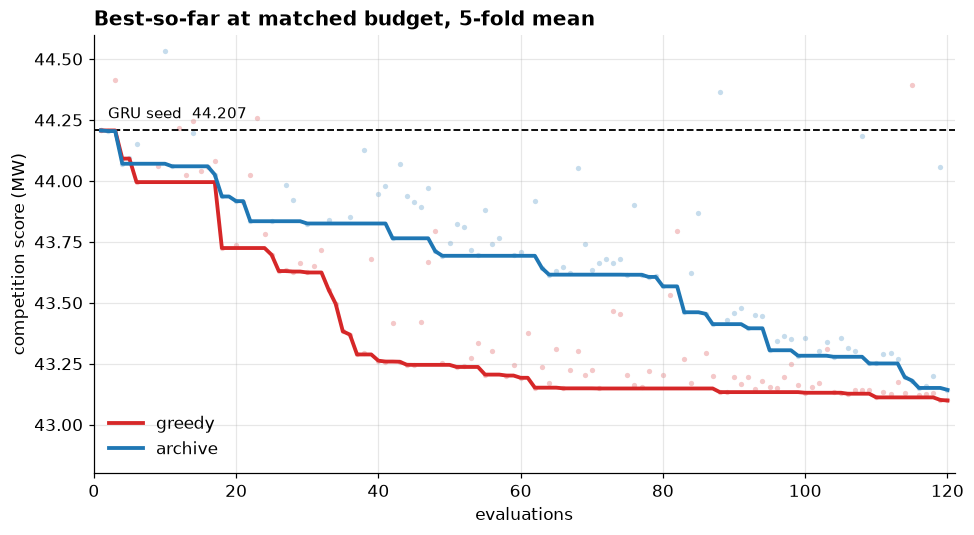

       greedy  archive    gap
evals                        
20     43.724   43.917 -0.193
40     43.262   43.825 -0.563
60     43.192   43.692 -0.500
80     43.148   43.567 -0.419
100    43.131   43.282 -0.151
120    43.099   43.143 -0.044


In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for k, df in runs.items():
    v = df[df.valid]
    ax.scatter(v.n, v.score, s=12, color=COL[k], alpha=0.25, linewidths=0)
    ax.plot(df.n, df.best, color=COL[k], lw=2.5, label=k, zorder=3)
ax.axhline(SEED, color="black", lw=1.2, ls="--")
ax.annotate(f"GRU seed  {SEED:.3f}", xy=(2, SEED + 0.05), fontsize=10)
ax.set_xlabel("evaluations"); ax.set_ylabel("validation score (MW)")
ax.set_title("Best-so-far VALIDATION at matched budget, 5-fold mean",
             loc="left", fontsize=13, weight="bold")
ax.set_xlim(0, 121); ax.set_ylim(42.8, 44.6)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "trajectory.png"); plt.show()

ck = pd.DataFrame({k: [df.best.iloc[j - 1] for j in (20, 40, 60, 80, 100, 120)]
                   for k, df in runs.items()},
                  index=[20, 40, 60, 80, 100, 120]).round(3)
ck["gap"] = (ck.greedy - ck.archive).round(3)
ck.index.name = "evals"
print(ck.to_string())

## 3. Per-fold behaviour

The reason for cross-validating. A change that lowers the mean by improving one fold
while hurting three is a period-specific artifact, and the single contiguous split
could not see the difference.

`fold_std` is the spread across the five folds — falling std means the program is
getting more consistent across periods, not just better on average.

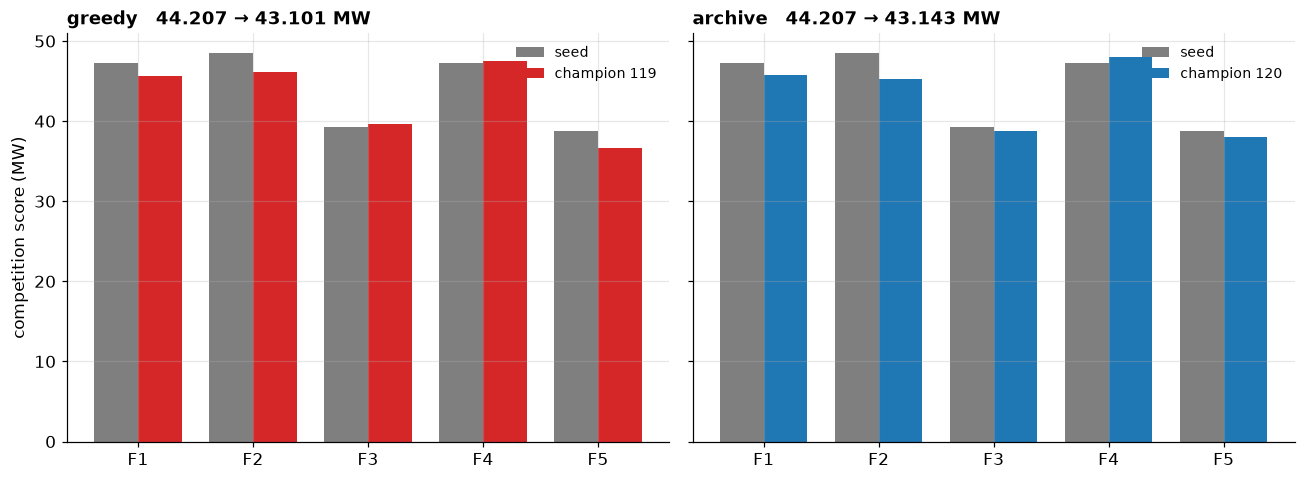

per-fold, seed vs champion
  greedy   gain by fold {'F1': np.float64(1.678), 'F2': np.float64(2.382), 'F3': np.float64(-0.442), 'F4': np.float64(-0.186), 'F5': np.float64(2.095)}   fold_std 4.298 → 4.200
  archive  gain by fold {'F1': np.float64(1.575), 'F2': np.float64(3.278), 'F3': np.float64(0.461), 'F4': np.float64(-0.749), 'F5': np.float64(0.755)}   fold_std 4.298 → 4.019


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (k, df) in zip(axes, runs.items()):
    champ = CHAMP[k]
    seed  = df.iloc[0]
    x = np.arange(len(FOLDS)); w = 0.38
    ax.bar(x - w/2, [seed[f]  for f in FOLDS], w, color="tab:gray", label="seed")
    ax.bar(x + w/2, [champ[f] for f in FOLDS], w, color=COL[k], label=f"champion {champ.id}")
    ax.set_xticks(x); ax.set_xticklabels(FOLDS)
    ax.set_title(f"{k}   {seed.score:.3f} → {champ.score:.3f} MW",
                 loc="left", fontsize=12, weight="bold")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("validation score (MW)")
fig.tight_layout(); fig.savefig(FIGS / "per_fold_seed_vs_champion.png"); plt.show()

print("per-fold, seed vs champion")
for k, df in runs.items():
    champ, seed = CHAMP[k], df.iloc[0]
    row = {f: round(seed[f] - champ[f], 3) for f in FOLDS}   # positive = champion better
    print(f"  {k:8s} gain by fold {row}   fold_std {seed.fold_std:.3f} → {champ.fold_std:.3f}")

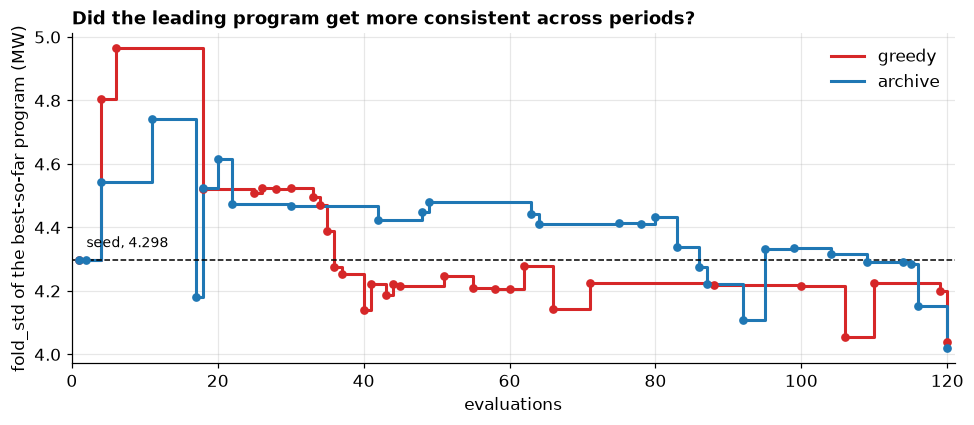

fold_std, seed -> champion
  greedy   4.298 -> 4.200
  archive  4.298 -> 4.019


In [6]:
# fold_std of the BEST-SO-FAR program, not of every attempt. The question is
# whether each arm's chosen program became more consistent across periods as its
# mean score improved -- plotting all 120 attempts just shows scatter.
fig, ax = plt.subplots(figsize=(9, 4))
for k, df in runs.items():
    v = df[df.valid].copy()
    keep_idx = v.score.cummin() == v.score        # rows that set a new best
    frontier = v[keep_idx]
    ax.step(frontier.n, frontier.fold_std, color=COL[k], lw=2, where="post", label=k)
    ax.scatter(frontier.n, frontier.fold_std, s=22, color=COL[k], zorder=3)
ax.axhline(runs["greedy"].fold_std.iloc[0], color="black", lw=1, ls="--")
ax.annotate("seed, 4.298", xy=(2, runs["greedy"].fold_std.iloc[0] + 0.04), fontsize=9)
ax.set_xlabel("evaluations"); ax.set_ylabel("fold_std of the best-so-far program (validation, MW)")
ax.set_title("Did the leading program get more consistent across periods?",
             loc="left", fontsize=12, weight="bold")
ax.set_xlim(0, 121); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "fold_std_frontier.png"); plt.show()

print("fold_std, seed -> champion")
for k, df in runs.items():
    print(f"  {k:8s} {df.fold_std.iloc[0]:.3f} -> {CHAMP[k].fold_std:.3f}")


## 4. Valley crossing (archive arm)

Under greedy a program scoring worse than its own parent is deleted by `git reset` and
cannot be edited again. So: was a program itself a regression on *its* parent? If yes,
greedy would no longer have it. Then did any child of it improve? Those are lineages
greedy structurally could not follow.

This is an existence claim, not a mean, so it does not depend on n=1.

In [7]:
a = runs["archive"]
score_of, parent_of = a.set_index("id").score.to_dict(), a.set_index("id").parent_id.to_dict()

def was_regression(pid):
    gp = parent_of.get(pid)
    if gp is None or gp not in score_of or pid not in score_of: return False
    if pd.isna(score_of[gp]) or pd.isna(score_of[pid]):        return False
    return score_of[pid] > score_of[gp]

lin = a[a.valid].copy()
lin["parent_score"] = lin.parent_id.map(score_of)
lin = lin.dropna(subset=["parent_score"])
lin["gain"] = lin.parent_score - lin.score
lin["parent_was_regression"] = lin.parent_id.map(was_regression)

revived = lin[lin.parent_was_regression & (lin.gain > 0)].sort_values("gain", ascending=False)
print(f"{len(revived)} children improved on a parent greedy would have deleted\n")
print(revived[["id", "score", "parent_id", "parent_score", "gain"]].head(10).round(3).to_string(index=False))
beats = revived[revived.score < runs["greedy"].best.iloc[-1]]
print(f"\nof those, {len(beats)} ended below greedy's final {runs['greedy'].best.iloc[-1]:.3f} MW")

11 children improved on a parent greedy would have deleted

 id  score parent_id  parent_score  gain
038 44.128       032        46.705 2.577
077 43.615       076        43.902 0.287
095 43.305       094        43.445 0.140
056 43.740       033        43.841 0.100
092 43.395       091        43.479 0.084
063 43.642       060        43.708 0.066
106 43.315       105        43.357 0.041
067 43.621       066        43.647 0.025
054 43.696       053        43.717 0.021
098 43.350       097        43.362 0.012

of those, 0 ended below greedy's final 43.099 MW


## 5. Largest single edits

In [8]:
# "Gain over parent" measures different things in each arm and must be split.
#
#   greedy  - the parent is always the current best, so a gain is a real advance
#             on the frontier.
#   archive - the parent is whatever the sampler drew, often far worse than the
#             arm's own best. A large gain can be pure catch-up: archive's 038
#             "gained" 2.577 MW over parent 032 while scoring 0.30 WORSE than the
#             arm's standing best at the time.
#
# advanced_frontier separates the two: True only if the child beat the best
# score the arm had before that evaluation.
def gains(df):
    s = df.set_index("id").score.to_dict()
    g = df[df.valid].copy()
    g["parent_score"] = g.parent_id.map(s)
    g = g.dropna(subset=["parent_score"])
    g["gain"] = g.parent_score - g.score
    prev_best = df.score.cummin().shift(1)
    g["prev_best"] = prev_best.reindex(g.index)
    g["advanced_frontier"] = g.score < g.prev_best
    g["frontier_gain"] = (g.prev_best - g.score).where(g.advanced_frontier)
    return g

COLS = ["id", "parent_id", "parent_score", "score", "gain", "advanced_frontier"]
for k, df in runs.items():
    g = gains(df)
    print(f"=== {k}: largest gain over the parent it was handed")
    print(g.sort_values("gain", ascending=False).head(3)[COLS].round(3).to_string(index=False))
    print(f"\n=== {k}: largest genuine advance of the frontier")
    print(g.sort_values("frontier_gain", ascending=False).head(3)
          [["id", "parent_id", "prev_best", "score", "frontier_gain"]].round(3).to_string(index=False), "\n")


=== greedy: largest gain over the parent it was handed
 id parent_id  parent_score  score  gain  advanced_frontier
018       013        44.025 43.724 0.301               True
004       001        44.207 44.091 0.115               True
035       034        43.495 43.383 0.112               True

=== greedy: largest genuine advance of the frontier
 id parent_id  prev_best  score  frontier_gain
018       013     43.995 43.724          0.270
004       001     44.207 44.091          0.115
035       034     43.495 43.383          0.112 

=== archive: largest gain over the parent it was handed
 id parent_id  parent_score  score  gain  advanced_frontier
038       032        46.705 44.128 2.577              False
049       013        45.760 43.692 2.067               True
025       013        45.760 43.835 1.925              False

=== archive: largest genuine advance of the frontier
 id parent_id  prev_best  score  frontier_gain
004       002     44.204 44.070          0.134
095       094     

In [9]:
# Rows that scored better than the standing best but were NOT adopted.
# Greedy's row 120 is the notable case: 43.0989, lower than any keep, discarded
# because the gain sat inside the ~0.01 MW threshold the agent applied all run.
g = runs["greedy"]
kept_best = g[g.status == "keep"].score.min()
below = g[g.valid & (g.score < kept_best) & (g.status != "keep")]
print("greedy: rows scoring below the best KEEP but not adopted")
print(below[["id", "score", "status", "description"]].round(4).to_string(index=False)
      if len(below) else "  none")

# How often did each arm note fold agreement in its own descriptions?
print("\nrows whose description mentions fold agreement")
for k, df in runs.items():
    d = df.description.astype(str).str.lower()
    n = d.str.contains("all five folds|all 5 folds|better on . of 5|of 5 folds").sum()
    print(f"  {k:8s} {n:3d} of {len(df)}")


greedy: rows scoring below the best KEEP but not adopted
 id   score  status                                                                                                                                       description
120 43.0989 discard two-regime response stacked on the final program: turbines idle more than half the last hour get damped coefficients (106 gave -0.007 standalone)

rows whose description mentions fold agreement
  greedy    34 of 120
  archive   16 of 120


In [10]:
import difflib

def show_diff(arm_dir, parent, child, context=2, max_lines=60):
    a = (WS / arm_dir / "archive" / f"{parent}.py").read_text().splitlines()
    b = (WS / arm_dir / "archive" / f"{child}.py").read_text().splitlines()
    print(f"--- {arm_dir}: {parent}.py ({len(a)} lines) -> {child}.py ({len(b)} lines)")
    d = list(difflib.unified_diff(a, b, lineterm="", n=context))
    print("\n".join(d[:max_lines]))
    if len(d) > max_lines: print(f"... {len(d)-max_lines} more diff lines")

for k, arm_dir in ARMS.items():
    top = gains(runs[k]).iloc[0]
    show_diff(arm_dir, top.parent_id, top.id)
    print("\n" + "=" * 92 + "\n")

--- greedy-cv: 001.py (1069 lines) -> 002.py (1207 lines)
--- 
+++ 
@@ -87,5 +87,42 @@
 
 # Clip negative predictions to zero. False matches the official baseline.
+# Measured no-op for this model: its minimum output over a full horizon is
+# ~245 kW, so nothing is ever clipped.
 CLIP_NEGATIVE = False
+
+# ---------------------------------------------------------------------------
+# METRIC-ANCHORED LONG-HORIZON CORRECTION
+#
+# The GRU is fitted to EVERY training record, but the official grader excludes
+# invalid records -- fault, curtailment, out-of-range sensors -- from the ground
+# truth it scores against. On F1's fold_train.csv that is 23.5% of rows, and
+# they sit at or below zero, so the target distribution the model learns is
+# contaminated downwards relative to the one it is scored on:
+#
+#   all-record training mean            362.1 kW  (std across turbines 39.2)
+#   model's own long-horizon asymptote  354.7 kW  (std 37.7)   corr 0.96
+#   scored-eligible metric-optimal

In [11]:
# The single edit that advanced each arm's frontier the most: what it changed,
# what the agent said about it, and where in the horizon it paid off.
import textwrap
for k, arm_dir in ARMS.items():
    g = gains(runs[k])
    top = g.sort_values("frontier_gain", ascending=False).iloc[0]
    print("=" * 92)
    print(f"{k}: {top.parent_id} -> {top.id}   {top.prev_best:.3f} -> {top.score:.3f}  "
          f"({top.frontier_gain:.3f} MW)")
    print(textwrap.fill(str(top.description), 90), "\n")
    print("per fold:")
    par = runs[k].set_index("id").loc[top.parent_id]
    for f in FOLDS:
        d = par[f] - top[f]
        print(f"   {f}  {par[f]:7.3f} -> {top[f]:7.3f}   {d:+.3f}")
    print()
    show_diff(arm_dir, top.parent_id, top.id, context=1, max_lines=45)
    print()


greedy: 013 -> 018   43.995 -> 43.724  (0.270 MW)
50/50 ensemble of GRU (ckpt_005) and linear shrinkage; beats BOTH parents - better than
GRU on 4 of 5 folds and than linear on 3 of 5 - genuine cross-class decorrelation unlike
the two-GRU ensemble in 012 

per fold:
   F1   46.847 ->  46.536   +0.311
   F2   47.803 ->  47.851   -0.048
   F3   39.725 ->  39.547   +0.179
   F4   47.258 ->  47.635   -0.377
   F5   38.493 ->  37.052   +1.441

--- greedy-cv: 013.py (172 lines) -> 018.py (1261 lines)
--- 
+++ 
@@ -2,45 +2,1103 @@
 """
-path: windevolve_sdwpf/arms/karpathy/ws/greedy-cv/forecaster.py
+path: windevolve_sdwpf/baseline_models/gru/gru_baseline.py
 
 Description:
-    Linear shrinkage forecaster for SDWPF 48h-ahead active power. Each turbine's
-    forecast is its recent level pulled towards its own climatological mean at a
-    rate fitted, per fold, from that fold's training data:
-
-        pred_t(h) = mu_t + beta(h) * (x_now_t - mu_t)
-
-    where mu_t is turbine t's mean power

## 6. What the forecasts actually look like

Scores compress 75 windows into one number. This runs the seed and each champion on a
real validation window and plots the 48-hour forecast against the truth.

Reading the outfile here is fine — this is analysis, not search. The agents never had
access to it.
**Axis labels.** Every plot below is scored on the *validation* folds, never on
`final_phase_test`. Axes say "validation" for that reason — the only place a test
score appears in this notebook is section 7.

**Window selection.** `WINDOWS` should hold three (fold, window) pairs so the grid
below is 3×3: three turbines down the rows, three windows across the columns.


In [12]:
import importlib.util, os, shutil, sys

FOLDS_ROOT = Path(os.environ.get(
    "SDWPF_FOLDS_ROOT", ROOT / "evaluation/splits_rolling_5x30"))
CAP, OUT_LEN = 134, 288

def predict(arm_dir, prog_id, fold="F5", window="0001"):
    """Run one program on one validation window. Returns (134, 288) in kW.

    The program is copied to the worktree root first: it resolves checkpoint
    paths relative to its own file location, so running it from archive/ would
    look for weights in archive/checkpoints/.
    """
    wd  = WS / arm_dir
    tmp = wd / f"_pred_{arm_dir}_{prog_id}.py"
    shutil.copyfile(wd / "archive" / f"{prog_id}.py", tmp)
    cwd = os.getcwd()
    try:
        os.chdir(wd)
        name = f"pred_{arm_dir.replace('-', '_')}_{prog_id}"
        spec = importlib.util.spec_from_file_location(name, tmp)
        mod  = importlib.util.module_from_spec(spec)
        sys.modules[name] = mod
        spec.loader.exec_module(mod)
        envs = {
            "path_to_test_x": str(FOLDS_ROOT / fold / "windows" / "infile" / f"{window}in.csv"),
            "path_to_train":  str(FOLDS_ROOT / fold / "fold_train.csv"),
            "fold": fold, "capacity": CAP, "output_len": OUT_LEN,
        }
        return np.asarray(mod.forecast(envs)).reshape(CAP, OUT_LEN)
    finally:
        os.chdir(cwd)
        tmp.unlink(missing_ok=True)

def truth(fold="F5", window="0001"):
    df = pd.read_csv(FOLDS_ROOT / fold / "windows" / "outfile" / f"{window}out.csv")
    return df["Patv"].to_numpy(dtype=float).reshape(CAP, OUT_LEN)

champs = {k: CHAMP[k].id for k in ARMS}
print("champions:", champs)

# Two windows from different folds: one late-period (F5) and one early (F1),
# so the plots are not a single lucky or unlucky day.
WINDOWS = [("F5", "0001"), ("F1", "0008")]

def run_all(fold, window):
    p = {"seed": predict(ARMS["greedy"], "001", fold, window)}
    for k, arm_dir in ARMS.items():
        p[k] = predict(arm_dir, champs[k], fold, window)
    return truth(fold, window), p

CASES = {(f, w): run_all(f, w) for f, w in WINDOWS}
FOLD, WINDOW = WINDOWS[0]
y, preds = CASES[(FOLD, WINDOW)]
print({k: v.shape for k, v in preds.items()})

champions: {'greedy': '119', 'archive': '120'}
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/checkpoints/F5
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/.cache/ckpt_005/F5
[gru] NOTE: 134 checkpoint(s) came from a partial training run (e.g. turbine 0). With per-turbine seeding this is reproducible and shardable, so it is only a problem if the run is INCOMPLETE. Under official single-stream seeding it would also fail to reproduce the published RNG stream.
[gru] loading 134 checkpoints from: /home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/.cache/ckpt_085/F5
[gru] NOTE: 134 checkpoint(s) came from a partial training run (e.g. turbine 0). With per-turbine seeding this is reproducible and shardable, so it is only a problem if the run is INCOMPLETE. Under official single-stream seeding it would also fail to reproduce the published RNG stream.

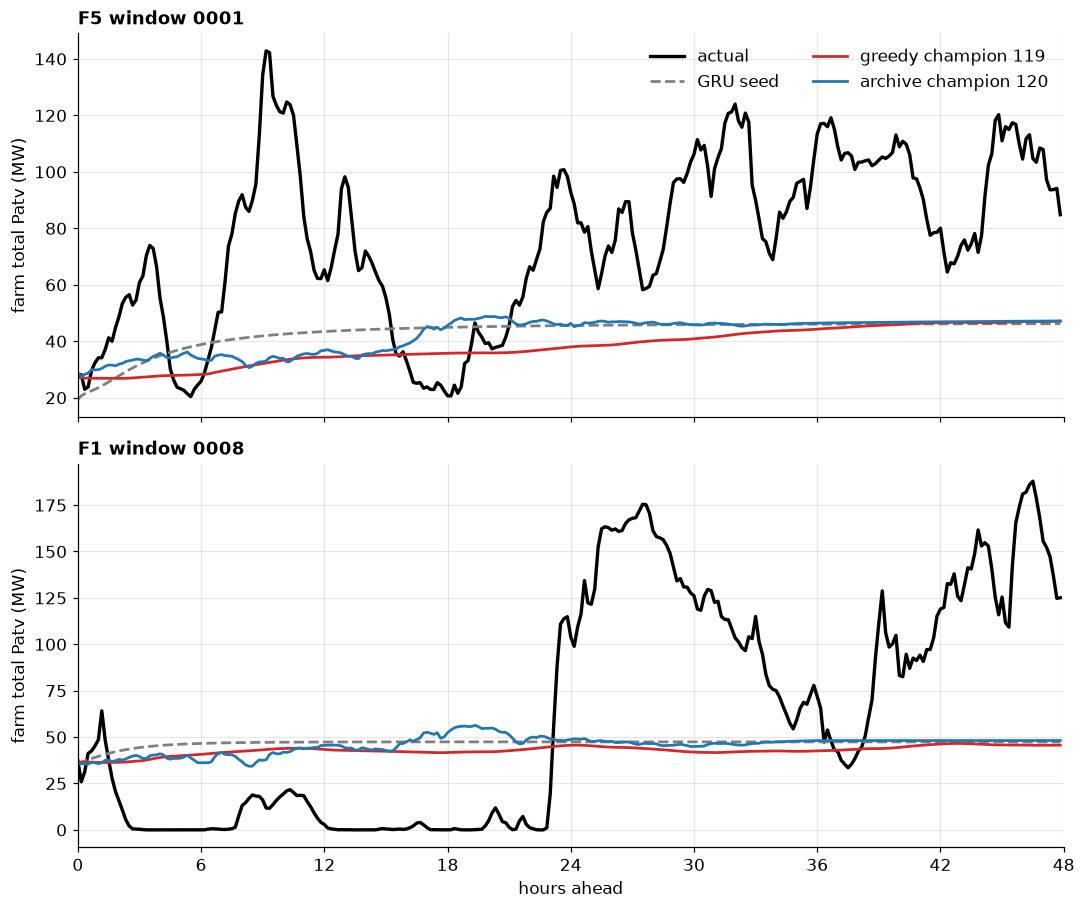

In [13]:
hours = np.arange(OUT_LEN) / 6.0
fig, axes = plt.subplots(len(WINDOWS), 1, figsize=(10, 4.2 * len(WINDOWS)), sharex=True)
for ax, (fold, window) in zip(np.atleast_1d(axes), WINDOWS):
    yy, pp = CASES[(fold, window)]
    ax.plot(hours, np.nansum(yy, axis=0) / 1000, color="black", lw=2.2, label="actual")
    ax.plot(hours, pp["seed"].sum(0) / 1000, color="tab:gray", lw=1.8, ls="--", label="GRU seed")
    for k in ARMS:
        ax.plot(hours, pp[k].sum(0) / 1000, color=COL[k], lw=1.8,
                label=f"{k} champion {champs[k]}")
    ax.set_ylabel("farm total Patv (MW)")
    ax.set_title(f"{fold} window {window}", loc="left", fontsize=12, weight="bold")
    ax.set_xlim(0, 48); ax.set_xticks(range(0, 49, 6))
np.atleast_1d(axes)[0].legend(frameon=False, ncol=2)
np.atleast_1d(axes)[-1].set_xlabel("hours ahead")
fig.tight_layout(); fig.savefig(FIGS / "forecast_farm_total.png"); plt.show()


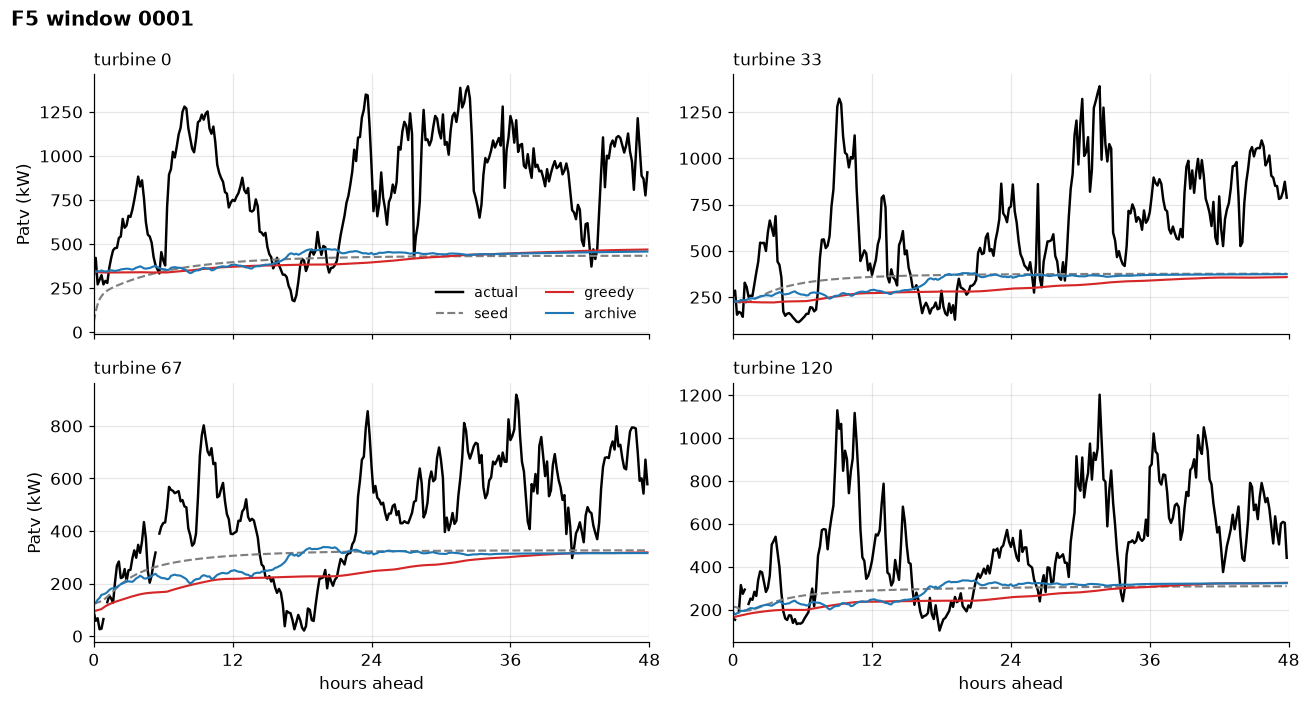

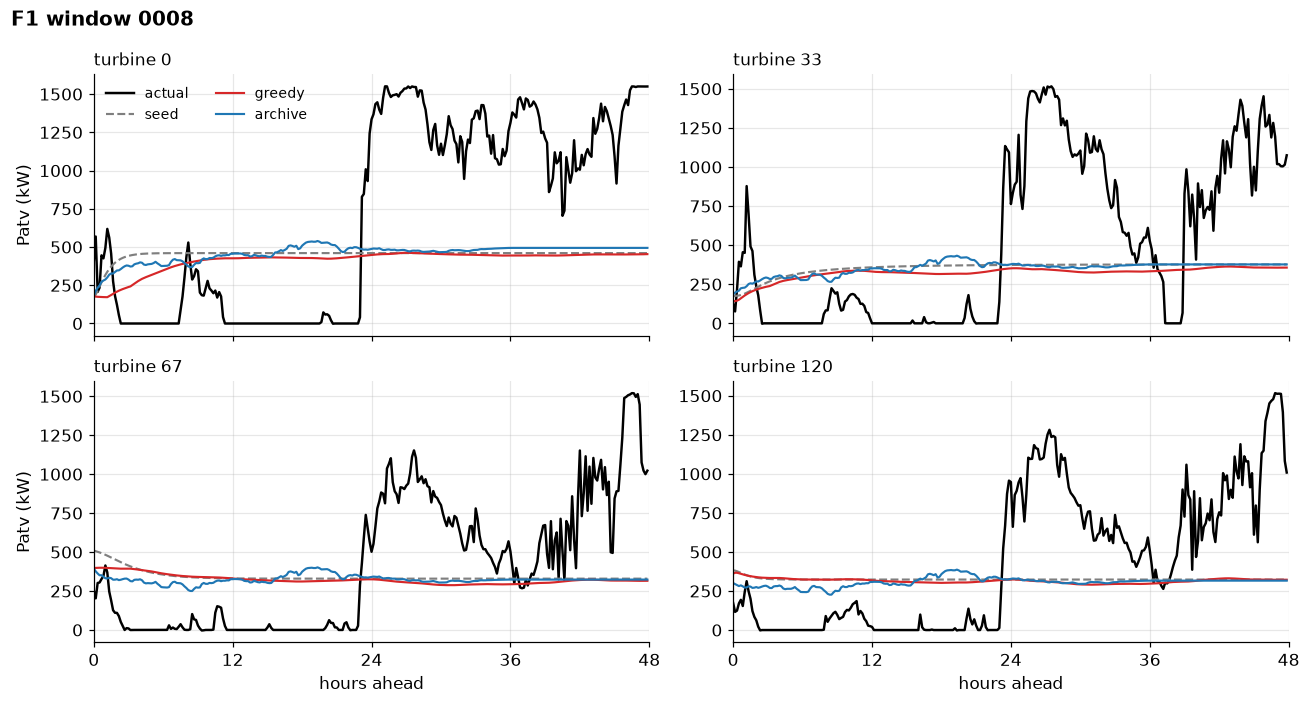

In [14]:
# THREE turbines x THREE windows, same layout so rows and columns are comparable.
# Rows are turbines, columns are windows: read across a row to see one turbine in
# three different periods, down a column to see one window across three turbines.
SEL = [0, 67, 120]

def turbine_grid(sel=SEL, windows=None):
    windows = windows or WINDOWS
    fig, axes = plt.subplots(len(sel), len(windows),
                             figsize=(5.0 * len(windows), 3.1 * len(sel)),
                             sharex=True)
    axes = np.atleast_2d(axes)
    for r, t in enumerate(sel):
        for c, (fold, window) in enumerate(windows):
            ax = axes[r, c]
            yy, pp = CASES[(fold, window)]
            ax.plot(hours, yy[t], color="black", lw=1.5, label="actual")
            ax.plot(hours, pp["seed"][t], color="tab:gray", lw=1.3, ls="--", label="seed")
            for k in ARMS:
                ax.plot(hours, pp[k][t], color=COL[k], lw=1.3, label=k)
            ax.set_xlim(0, 48); ax.set_xticks(range(0, 49, 12))
            if r == 0:
                ax.set_title(f"{fold} window {window}", fontsize=11, weight="bold")
            if c == 0:
                ax.set_ylabel(f"turbine {t}\nPatv (kW)", fontsize=10)
    for ax in axes[-1]:
        ax.set_xlabel("hours ahead")
    axes[0, 0].legend(frameon=False, fontsize=8.5, ncol=2)
    fig.tight_layout()
    fig.savefig(FIGS / "forecast_turbine_grid.png")
    plt.show()

# Needs at least 3 entries in WINDOWS for a full 3x3. Add folds above if short.
turbine_grid()


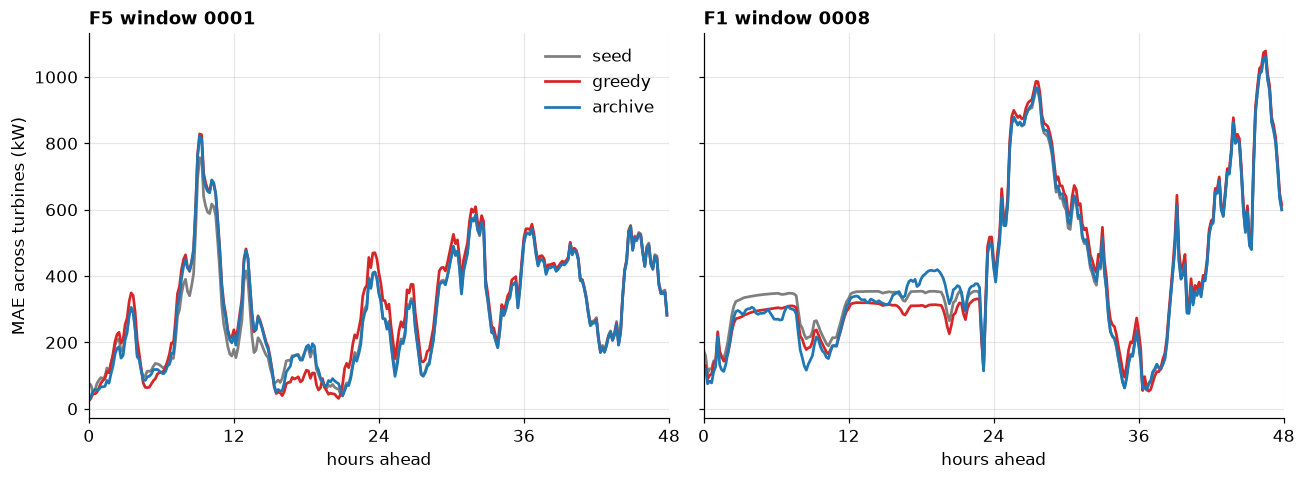

MAE (kW), first 6h vs last 6h
  F5 0001
    seed     first  146.42   last  364.73
    greedy   first  143.06   last  359.60
    archive  first  128.80   last  358.29
  F1 0008
    seed     first  267.77   last  752.40
    greedy   first  231.81   last  762.26
    archive  first  226.16   last  747.23


In [15]:
fig, axes = plt.subplots(1, len(WINDOWS), figsize=(6 * len(WINDOWS), 4.5), sharey=True)
for ax, (fold, window) in zip(np.atleast_1d(axes), WINDOWS):
    yy, pp = CASES[(fold, window)]
    for lab, col in [("seed", "tab:gray")] + [(k, COL[k]) for k in ARMS]:
        ax.plot(hours, np.nanmean(np.abs(pp[lab] - yy), axis=0), color=col, lw=1.8, label=lab)
    ax.set_xlabel("hours ahead")
    ax.set_title(f"{fold} window {window}", loc="left", fontsize=12, weight="bold")
    ax.set_xlim(0, 48); ax.set_xticks(range(0, 49, 12))
np.atleast_1d(axes)[0].set_ylabel("MAE across turbines (kW)")
np.atleast_1d(axes)[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "error_by_lead_time.png"); plt.show()

print("MAE (kW), first 6h vs last 6h")
for fold, window in WINDOWS:
    yy, pp = CASES[(fold, window)]
    print(f"  {fold} {window}")
    for lab in ["seed"] + list(ARMS):
        e = np.abs(pp[lab] - yy)
        print(f"    {lab:8s} first {np.nanmean(e[:, :36]):7.2f}   last {np.nanmean(e[:, -36:]):7.2f}")


## 7. Competition test set

`evaluation/competition_score.py` over the locked `final_phase_test` (142 windows).
Run once per program, never as a search signal.

**Checkpoints must be trained on the full 245 days** for these numbers to sit in the
same table as the published baselines (climatology 50.487, ARMA 49.605, XGBoost
46.804, GRU 46.809) — that column was produced that way. The per-fold weights exist
for cross-validation only, where fold k must not see its own validation block; the
test set is days 246+, so training on 1–245 leaks nothing and is the protocol the
competition intended.

Both champions are ensembles with several hardcoded `{fold}` templates, so the
`SDWPF_GRU_CHECKPOINTS` override alone is not enough — every template is rewritten
in the copied file. Full-data weights live in directories named `FULL`, so the same
substitution machinery resolves them.

Run `retrain_full.sh` first (~4–5 h on an idle GPU).

In [16]:
import subprocess

TEST_DIR = os.environ.get(
    "SDWPF_TEST_DIR", str(Path.home() / "srip/wind_forecasting_data/sdwpf_kddcup/final_phase_test"))

def pin_fold(src, pin):
    """Replace the {fold} placeholder ONLY where a checkpoint path is built.

    A blanket src.replace("{fold}", pin) also rewrites the guard that detects an
    unresolved placeholder and the error message it raises: the guard then matches
    on the substituted word and the message's .format() fails with KeyError.
    Restricting the edit to os.path.join lines leaves the guard intact.
    """
    out, n = [], 0
    for line in src.splitlines(keepends=True):
        if "os.path.join" in line and '"{fold}"' in line:
            line = line.replace('"{fold}"', '"' + pin + '"'); n += 1
        out.append(line)
    return "".join(out), n

def test_score(arm_dir, prog_id, pin="FULL", ckpt=None):
    wd  = WS / arm_dir
    src = (wd / "archive" / (prog_id + ".py")).read_text()
    n = 0
    if pin is not None:
        src, n = pin_fold(src, pin)
    tmp = wd / ("_champion_" + prog_id + ".py")
    tmp.write_text(src)
    env = {**os.environ, "SDWPF_TEST_DIR": TEST_DIR}
    env.pop("SDWPF_GRU_CHECKPOINTS", None)
    if ckpt:
        env["SDWPF_GRU_CHECKPOINTS"] = ckpt
    try:
        out = subprocess.run(
            ["python", str(ROOT / "evaluation" / "competition_score.py"), str(tmp)],
            cwd=wd, env=env, capture_output=True, text=True, timeout=14400)
    finally:
        tmp.unlink(missing_ok=True)
    keys = ("competition_score", "total_mae", "total_rmse", "accuracy", "windows")
    tail = [l for l in out.stdout.splitlines() if any(k in l for k in keys)]
    print("=== {} {}   ({} path templates -> {})".format(arm_dir, prog_id, n, pin))
    print("\n".join(tail) if tail else out.stdout[-1200:])
    if out.returncode:
        print("STDERR:", out.stderr[-900:])
    print()
    return out


In [17]:
# Anchor check: the seed program on the FULL-data checkpoints should reproduce the
# 46.809 already in the baseline table. If it does not, the champions' numbers will
# not be comparable to that table either, and the discrepancy has to be resolved
# before anything else is reported.
CKPT_FULL = ROOT / "baselines/gru/ckpt_full"
print("ckpt_full:", CKPT_FULL, "|", len(list(CKPT_FULL.glob("model_*.pt"))), "models")

_ = test_score(ARMS["greedy"], "001", pin=None, ckpt=str(CKPT_FULL))
print("expected 46.809 from the baseline table")


ckpt_full: /home/dorsa/srip/windevolve_sdwpf/baselines/gru/ckpt_full | 134 models
=== greedy-cv 001   (0 path templates -> None)
  total_mae         : 41.993974
  total_rmse        : 51.623626
  competition_score : 46.808800   (0.5*(rmse+mae), lower is better)
  accuracy          : 60.6515%
  windows           : 142

expected 46.809 from the baseline table


In [18]:
# Both champions on full-data weights. Run retrain_full.sh first.
for d in [WS / ARMS["greedy"] / ".cache" / "ckpt_005" / "FULL",
          WS / ARMS["greedy"] / ".cache" / "ckpt_085" / "FULL",
          WS / ARMS["archive"] / ".cache" / "ckpt_015" / "FULL",
          WS / ARMS["archive"] / ".cache" / "ckpt_009" / "FULL",
          WS / ARMS["archive"] / "checkpoints" / "FULL"]:
    print(f"{str(d):72s} {len(list(d.glob('model_*.pt'))) if d.is_dir() else 'MISSING':>8}")

_ = test_score(ARMS["greedy"],  CHAMP["greedy"].id,  pin="FULL")
_ = test_score(ARMS["archive"], CHAMP["archive"].id, pin="FULL")


/home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/.cache/ckpt_005/FULL      134
/home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/greedy-cv/.cache/ckpt_085/FULL      134
/home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/archive-cv/.cache/ckpt_015/FULL      134
/home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/archive-cv/.cache/ckpt_009/FULL        1
/home/dorsa/srip/windevolve_sdwpf/runs/search_policy_cv__aug14/archive-cv/checkpoints/FULL      134
=== greedy-cv 119   (3 path templates -> FULL)
  total_mae         : 42.483949
  total_rmse        : 52.834378
  competition_score : 47.659164   (0.5*(rmse+mae), lower is better)
  accuracy          : 59.5867%
  windows           : 142

=== archive-cv 120   (2 path templates -> FULL)
  total_mae         : 41.833921
  total_rmse        : 51.628328
  competition_score : 46.731124   (0.5*(rmse+mae), lower is better)
  accuracy          : 60.5953%
  windows           : 142



In [19]:
# Fill in the three test values from the cells above.
# Baseline table (all trained on the full 245 days):
#   climatology 50.487 | ARMA 49.605 | XGBoost 46.804 | GRU 46.809 | Baidu published 47.850
res = pd.DataFrame({
    "cv_5fold": [SEED, CHAMP["greedy"].score, CHAMP["archive"].score],
    "test":     [np.nan, np.nan, np.nan],
}, index=["GRU seed", f"greedy {CHAMP['greedy'].id}", f"archive {CHAMP['archive'].id}"])
res["cv_to_test_gap"]  = (res.test - res.cv_5fold).round(3)
res["vs_seed_on_test"] = (res.test - res.test.iloc[0]).round(3)
res["test_error_pct"]  = (res.test / CAPACITY * 100).round(2)
print(res.round(3).to_string())

print("""
The comparison this run exists to make — did 5-fold CV shrink the generalisation gap?

  aug10, single contiguous split (24 windows, days 198-245)
    seed     44.537 val -> 46.809 test   gap 2.272
    greedy   43.728     -> 47.738        gap 4.010
    archive  42.863     -> 48.209        gap 5.346
    both champions ended WORSE on test than the seed they started from.

  aug14, 5-fold rolling origin (75 windows)
    fill the gaps in above and compare. If the champion gaps land near the seed's
    rather than at 4-5 MW, the split change did its job.""")


             cv_5fold  test  cv_to_test_gap  vs_seed_on_test  test_error_pct
GRU seed       44.207   NaN             NaN              NaN             NaN
greedy 119     43.101   NaN             NaN              NaN             NaN
archive 120    43.143   NaN             NaN              NaN             NaN

The comparison this run exists to make — did 5-fold CV shrink the generalisation gap?

  aug10, single contiguous split (24 windows, days 198-245)
    seed     44.537 val -> 46.809 test   gap 2.272
    greedy   43.728     -> 47.738        gap 4.010
    archive  42.863     -> 48.209        gap 5.346
    both champions ended WORSE on test than the seed they started from.

  aug14, 5-fold rolling origin (75 windows)
    fill the gaps in above and compare. If the champion gaps land near the seed's
    rather than at 4-5 MW, the split change did its job.


## 8. Is fold_std actually predictive?

The champions' ranking flipped between CV mean and test, and `fold_std` ordered them
the way test did. That is two data points. Before treating it as a finding, check
whether the two measures rank programs differently across the whole population — if
they agree everywhere, the flip was a coincidence of two numbers.

In [20]:
from scipy.stats import spearmanr

allp = pd.concat([df[df.valid].assign(arm=k) for k, df in runs.items()], ignore_index=True)
print(f"{len(allp)} scored programs across both arms\n")

rho, p = spearmanr(allp.score, allp.fold_std)
print(f"CV mean vs fold_std, all programs : rho {rho:+.3f}  (p {p:.3g})")
for k, df in runs.items():
    v = df[df.valid]
    r, pp = spearmanr(v.score, v.fold_std)
    print(f"  {k:8s} rho {r:+.3f}  (p {pp:.3g})  n={len(v)}")

print("\nIf rho is strongly positive the two measures mostly agree and ranking by")
print("either gives the same answer. Near zero means they are close to independent,")
print("so which one you select on genuinely matters.")

# how often do the two disagree on a pairwise comparison?
import itertools, random
rng = random.Random(0)
pairs = [rng.sample(range(len(allp)), 2) for _ in range(20000)]
disagree = sum(
    (allp.score.iloc[i] < allp.score.iloc[j]) != (allp.fold_std.iloc[i] < allp.fold_std.iloc[j])
    for i, j in pairs)
print(f"\nrandom program pairs where mean and fold_std disagree on which is better: "
      f"{disagree/len(pairs):.1%}")


223 scored programs across both arms

CV mean vs fold_std, all programs : rho +0.490  (p 7.66e-15)
  greedy   rho +0.295  (p 0.0015)  n=113
  archive  rho +0.596  (p 6.29e-12)  n=110

If rho is strongly positive the two measures mostly agree and ranking by
either gives the same answer. Near zero means they are close to independent,
so which one you select on genuinely matters.

random program pairs where mean and fold_std disagree on which is better: 31.1%


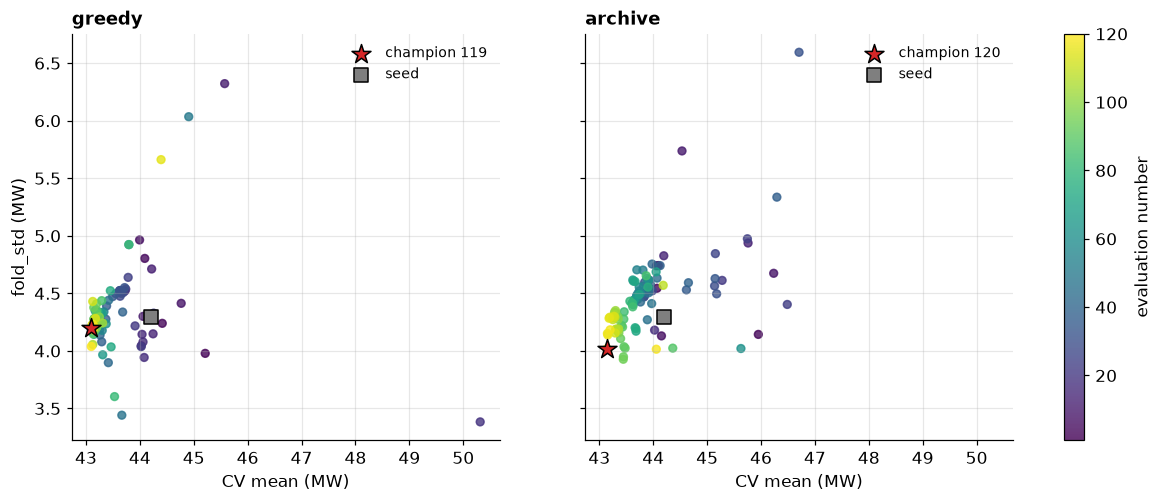

Lower-left is better on both measures. A program in the lower-right has a poor
mean but transfers consistently across periods; upper-left is the opposite and
is what selecting on the mean alone will pick up.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, (k, df) in zip(axes, runs.items()):
    v = df[df.valid]
    sc = ax.scatter(v.score, v.fold_std, c=v.n, cmap="viridis", s=26, alpha=0.8)
    ch = CHAMP[k]
    ax.scatter(ch.score, ch.fold_std, s=170, marker="*", color="tab:red",
               edgecolor="black", zorder=5, label=f"champion {ch.id}")
    ax.scatter(df.score.iloc[0], df.fold_std.iloc[0], s=90, marker="s",
               color="tab:gray", edgecolor="black", zorder=5, label="seed")
    ax.set_xlabel("validation mean (MW)")
    ax.set_title(k, loc="left", fontsize=12, weight="bold")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("fold_std of validation (MW)")
fig.colorbar(sc, ax=axes, label="evaluation number", fraction=0.03)
fig.savefig(FIGS / "mean_vs_foldstd.png", bbox_inches="tight")
plt.show()

print("Lower-left is better on both measures. A program in the lower-right has a poor")
print("mean but transfers consistently across periods; upper-left is the opposite and")
print("is what selecting on the mean alone will pick up.")


## 9. Test-scoring non-champions

The direct test of section 8. Pick programs spanning the mean/fold_std plane — good
mean with poor consistency, poor mean with good consistency, and both — score them on
the competition test set, and see which CV measure ranks them the way test does.

**Only programs that use the seed's own checkpoints can be scored cheaply.** Anything
loading a `.cache/ckpt_*` set needs those weights retrained on the full 245 days, which
is about an hour each. The filter below keeps the cheap ones.

In [22]:
import re

def cheap_to_score(arm_dir, prog_id):
    """True if the program needs no retrained .cache weights."""
    src = (WS / arm_dir / "archive" / (prog_id + ".py")).read_text()
    return not re.search(r"ckpt_\d+", src)

def candidates(k, n_per_corner=2):
    """Programs spanning the mean / fold_std plane, restricted to cheap ones."""
    v = runs[k][runs[k].valid].copy()
    v = v[[cheap_to_score(ARMS[k], i) for i in v.id]]
    if not len(v):
        return v
    v["mean_r"] = v.score.rank(pct=True)
    v["std_r"]  = v.fold_std.rank(pct=True)
    picks = pd.concat([
        v.nsmallest(n_per_corner, "mean_r"),                       # best mean
        v.nsmallest(n_per_corner, "std_r"),                        # most consistent
        v[(v.mean_r < 0.4) & (v.std_r > 0.6)].head(n_per_corner),  # good mean, poor std
        v[(v.mean_r > 0.6) & (v.std_r < 0.4)].head(n_per_corner),  # poor mean, good std
    ]).drop_duplicates(subset="id")
    return picks

for k in ARMS:
    c = candidates(k)
    print(f"=== {k}: {len(c)} cheap candidates")
    if len(c):
        print(c[["id", "score", "fold_std", "description"]].round(3).to_string(index=False)[:900])
    print()


=== greedy: 5 cheap candidates
 id  score  fold_std                                                                                                                                                                                                                                description
022 44.025     4.037                                         per-turbine beta instead of pooled (component test for a 3rd ensemble member); identical to pooled (-0.0006) because beta spread across turbines is only 0.033 vs mean 0.292 - no diversity to add
013 44.025     4.044 replace 134-GRU baseline with fitted linear shrinkage (172 lines no checkpoints no training); mean +0.03 vs parent ie a tie 30x inside noise but better on 3 of 5 folds and lower fold_std - KEPT ON THE SIMPLICITY CRITERION not on score
019 50.314     3.383                            gradient-boosted third model class (xgboost on history state + horizon); 6.6MW worse

=== archive: 4 cheap candidates
 id  score  fold_std               

In [23]:
# Score them. Programs with no {fold} templates take pin=None and the seed's
# full-data weights; the rest need pin="FULL" and their own retrained sets.
CKPT_FULL = str(ROOT / "baselines/gru/ckpt_full")

def quick_test(k, prog_id):
    src = (WS / ARMS[k] / "archive" / (prog_id + ".py")).read_text()
    has_tmpl = '"{fold}"' in src
    out = test_score(ARMS[k], prog_id,
                     pin="FULL" if has_tmpl else None,
                     ckpt=None if has_tmpl else CKPT_FULL)
    m = re.search(r"competition_score\s*:\s*([\d.]+)", out.stdout)
    return float(m.group(1)) if m else np.nan

rows = []
for k in ARMS:
    for pid in candidates(k).id:
        rows.append({"arm": k, "id": pid,
                     "cv_mean": runs[k].set_index("id").score[pid],
                     "fold_std": runs[k].set_index("id").fold_std[pid],
                     "test": quick_test(k, pid)})

probe = pd.DataFrame(rows).dropna(subset=["test"])
probe["gap"] = (probe.test - probe.cv_mean).round(3)
print(probe.round(3).to_string(index=False))


=== greedy-cv 022   (0 path templates -> None)
  total_mae         : 41.700467
  total_rmse        : 51.114110
  competition_score : 46.407289   (0.5*(rmse+mae), lower is better)
  accuracy          : 60.9869%
  windows           : 142

=== greedy-cv 013   (0 path templates -> None)
  total_mae         : 41.696287
  total_rmse        : 51.106604
  competition_score : 46.401445   (0.5*(rmse+mae), lower is better)
  accuracy          : 60.9944%
  windows           : 142

=== greedy-cv 019   (0 path templates -> None)
.2108335184912, MAE: 72.54692434953702, Score: 77.87887893401411, and Accuracy: 24.3275%

	The 112-th prediction -- RMSE: 46.80241185769705, MAE: 35.56565917471141, Score: 41.18403551620423, and Accuracy: 59.2523%

	The 113-th prediction -- RMSE: 77.77224394694073, MAE: 65.51823758635729, Score: 71.64524076664901, and Accuracy: 37.9986%

	The 114-th prediction -- RMSE: 58.90500770414999, MAE: 47.567181139522525, Score: 53.236094421836256, and Accuracy: 58.8242%

	The 115-th 

n = 7 programs scored on test

  CV mean  vs test : rho +0.500  (p 0.253)
  fold_std vs test : rho +0.750  (p 0.0522)

Positive rho means the measure ranks programs the way test does.
If fold_std beats the mean here, section 8's claim has support beyond the
two champions. With n this small neither is conclusive -- report rho and n,
not a verdict.


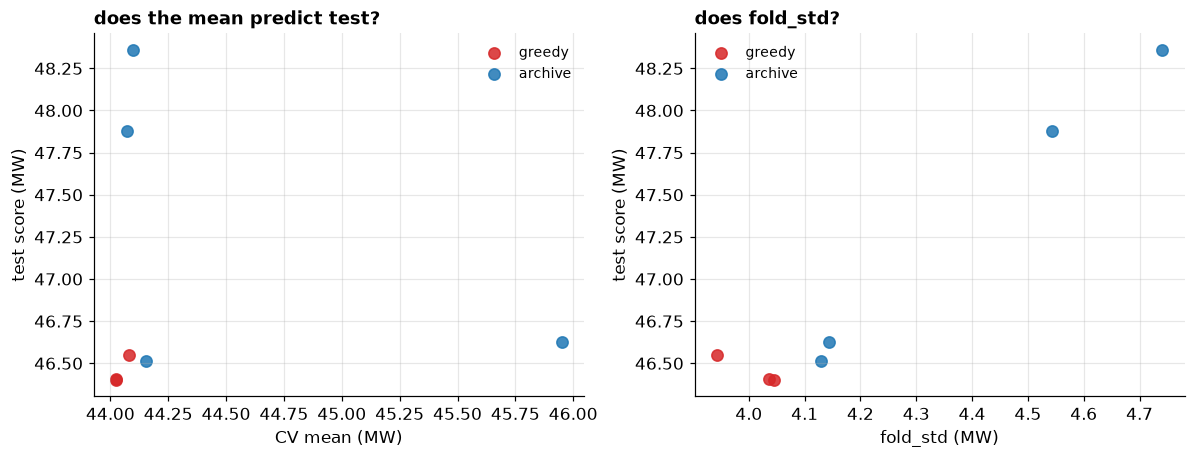

In [24]:
# Which CV measure ranks these the way test does?
if len(probe) >= 4:
    r_mean, p_mean = spearmanr(probe.cv_mean, probe.test)
    r_std,  p_std  = spearmanr(probe.fold_std, probe.test)
    print(f"n = {len(probe)} programs scored on test\n")
    print(f"  CV mean  vs test : rho {r_mean:+.3f}  (p {p_mean:.3g})")
    print(f"  fold_std vs test : rho {r_std:+.3f}  (p {p_std:.3g})")
    print("\nPositive rho means the measure ranks programs the way test does.")
    print("If fold_std beats the mean here, section 8's claim has support beyond the")
    print("two champions. With n this small neither is conclusive -- report rho and n,")
    print("not a verdict.")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
    for ax, (x, lab) in zip(axes, [(probe.cv_mean, "validation mean (MW)"),
                                   (probe.fold_std, "fold_std of validation (MW)")]):
        for k in ARMS:
            m = probe.arm == k
            ax.scatter(x[m], probe.test[m], s=55, color=COL[k], label=k, alpha=0.85)
        ax.set_xlabel(lab); ax.set_ylabel("test score (MW)")
        ax.legend(frameon=False, fontsize=9)
    axes[0].set_title("does the mean predict test?", loc="left", fontsize=12, weight="bold")
    axes[1].set_title("does fold_std?", loc="left", fontsize=12, weight="bold")
    fig.tight_layout(); fig.savefig(FIGS / "predictors_vs_test.png"); plt.show()
else:
    print(f"only {len(probe)} programs scored -- too few to correlate. Widen the")
    print("candidate filter, or retrain the .cache sets for a few more programs.")


## 10. Trace-level diagnostics

Sections 1–9 score programs. This section reads the *search process* instead,
following Pelleriti et al., *What Do Evolutionary Coding Agents Evolve?*
(arXiv:2605.20086), §5.1–5.2.

The motivation: a better final score is consistent with several different
mechanisms — new algorithmic structure, retuning a known strategy, recombining
what the model already knew, or overfitting the evaluator. The score alone cannot
tell them apart, so we look at the trajectory.

Four diagnostics in that paper. Two are computable from what we logged, one needs
a separate judge, one needs data we did not save:

| Diagnostic | Needs | Status here |
|---|---|---|
| Lineage depth / dead branches | `parent_id` | **computable** |
| Cycling rate | `archive/*.py` + `parent_id` | **computable** |
| Edit taxonomy | separate LLM judge, post-hoc | later |
| Replay stability | generating context per evaluation | **not logged** |

Their reference numbers, over 121 runs at 100 iterations each: median lineage
depth **6** (maths) / **4** (competitive programming); best-so-far arrival at
**0.75** / **0.49** of budget; cycling **~30%**.

Everything below runs off `runs`, `ARMS`, `WS` and `CHAMP` from cell 1 — no
external script.

### 10.1 Lineage — how far is the champion from the seed?

Walk `parent_id` backwards from the champion until we reach the seed; the length
of that chain is the lineage depth. Any program *not* on the chain is a dead
branch: it consumed an evaluation without being an ancestor of the winner.

**Use `CHAMP`, not the lowest score.** Cell 1 defines the champion as the best
row the arm actually *adopted*. Greedy's row 120 scored 43.099 — lower than
anything it kept — and the agent discarded it. Measuring lineage to row 120 would
credit greedy with a program its own policy rejected.

Caveat for the writeup: "not an ancestor" is not "useless". An archived program
can shape what the agent proposes later without ever being a direct parent, and
the parent–child graph cannot see that.

In [ ]:
def ancestry(pid, parent_of, root="000"):
    """Chain from pid back toward the seed: [pid, parent, ..., seed]."""
    chain, seen = [], set()
    cur = pid
    while cur and cur != root and cur in parent_of and cur not in seen:
        seen.add(cur); chain.append(cur); cur = parent_of[cur]
    return chain

lineage = {}
for k, df in runs.items():
    parent_of = df.set_index("id").parent_id.to_dict()
    chain     = ancestry(CHAMP[k].id, parent_of)
    lineage[k] = dict(
        champion   = CHAMP[k].id,
        depth      = len(chain) - 1,
        chain      = list(reversed(chain)),
        on_path    = len(set(chain)),
        dead_share = 1 - len(set(chain)) / len(df),
        depths     = [max(0, len(ancestry(i, parent_of)) - 1) for i in df.id],
        parent_of  = parent_of,
    )

tbl = pd.DataFrame({k: {
    "champion":               v["champion"],
    "champion CV (MW)":       round(CHAMP[k].score, 3),
    "champion lineage depth": v["depth"],
    "median depth (all)":     float(np.median(v["depths"])),
    "max depth":              int(np.max(v["depths"])),
    "programs on path":       v["on_path"],
    "dead-branch share":      f"{v['dead_share']:.1%}",
} for k, v in lineage.items()})
tbl["Pelleriti maths"] = ["—", "—", 6, "—", "—", "—", "most of budget"]
tbl["Pelleriti ALE"]   = ["—", "—", 4, "—", "—", "—", "most of budget"]
tbl

In [ ]:
# The champion's actual chain, and the consistency check that matters:
# greedy always mutates the incumbent, so its chain should be exactly its keeps.
for k, v in lineage.items():
    print(f"{k:8s} depth {v['depth']:2d} | ", " -> ".join(v["chain"]))

n_keep = (runs["greedy"].status == "keep").sum()
print(f"\ngreedy: {n_keep} keep rows, {lineage['greedy']['on_path']} programs on the "
      f"champion chain  ->  equal: {n_keep == lineage['greedy']['on_path']}")

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(0, max(max(v["depths"]) for v in lineage.values()) + 3, 2)
for k, v in lineage.items():
    ax.hist(v["depths"], bins=bins, alpha=0.7, color=COL[k], label=k, edgecolor="white")
ax.axvspan(4, 6, color="tab:red", alpha=0.12)
ax.text(6.4, ax.get_ylim()[1] * 0.92, "Pelleriti median 4-6", color="tab:red", fontsize=9)
for k, v in lineage.items():
    ax.axvline(v["depth"], color=COL[k], ls="--", lw=1.2)
ax.set_xlabel("Lineage depth (edits back to the seed)")
ax.set_ylabel("Programs"); ax.legend(frameon=False)
ax.set_title("Dashed lines mark each arm's champion", fontsize=10)
plt.tight_layout(); plt.savefig(FIGS / "lineage_depth.png"); plt.show()

### 10.2 Budget utilisation — when did the champion arrive?

Pelleriti describe a "jackpot-then-flat" pattern: a few early improvements, then
a long tail where nothing beats the incumbent. They quantify it as the normalised
iteration at which best-so-far last improved — 0.75 on maths, 0.49 on ALE.

If our arms land near 1.00, they had not converged, and the *budget* rather than
the search was the binding constraint.

In [ ]:
rows = []
for k, df in runs.items():
    d    = df.reset_index(drop=True)
    pool = d[d.status == "keep"] if (d.status == "keep").any() else d[d.valid]
    ids  = set(pool.id)

    best, arrival, curve = np.inf, None, []
    for i, r in d.iterrows():
        if r.id in ids and r.valid and r.score < best:
            best, arrival = r.score, i
        curve.append(best)
    half = len(curve) // 2
    lineage[k]["bsf_adopted"] = curve

    rows.append({
        "arm": k,
        "champion adopted at eval": arrival + 1,
        "normalised arrival":       round(arrival / (len(d) - 1), 3),
        "adopted best at halfway":  round(curve[half - 1], 3),
        "adopted best final":       round(curve[-1], 3),
        "gain in 2nd half (MW)":    round(curve[half - 1] - curve[-1], 3),
    })

bud = pd.DataFrame(rows).set_index("arm")
bud.loc["Pelleriti maths"] = ["—", 0.75, "—", "—", "—"]
bud.loc["Pelleriti ALE"]   = ["—", 0.49, "—", "—", "—"]
bud

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for k, df in runs.items():
    ax.plot(df.n, df.best, color=COL[k], lw=2.2, label=f"{k} (any scored row)")
    ax.plot(df.n, lineage[k]["bsf_adopted"], color=COL[k], lw=1.2, ls=":",
            label=f"{k} (adopted only)")
    ax.scatter([int(CHAMP[k].id)], [CHAMP[k].score], s=60, color=COL[k],
               edgecolors="k", zorder=5, linewidths=1)
ax.axhline(SEED, color="grey", ls="--", lw=1)
ax.text(3, SEED + 0.02, f"seed {SEED:.3f}", color="grey", fontsize=9)
ax.axvline(len(runs["greedy"]) // 2, color="tab:red", ls=":", lw=1)
ax.set_xlabel("Evaluation"); ax.set_ylabel("best-so-far validation score (MW)")
ax.set_ylim(43.0, 44.3); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig(FIGS / "no_plateau.png"); plt.show()

The two greedy curves separate at the very end: the solid line drops to 43.099
at evaluation 120, the dotted one does not, because that row was discarded. That
gap *is* the accept-threshold behaviour from section 5, seen from another angle.

### 10.3 Cycling — is the search re-adding code it already deleted?

For each parent→child edit: what share of added lines are **byte-identical** to
lines the *same lineage* deleted at an earlier evaluation? Deterministic, no LLM,
no judge — it is string comparison, which is why it is the most reproducible
measurement in the paper.

Two decisions that change the answer a lot:

1. **Code lines only.** Comment banners (`# -----`), blanks, bare punctuation
   **and docstring prose** are excluded. Rewritten files reflow their separators
   and their `Args:` / `Returns:` blocks constantly — unfiltered, that alone gives
   ~30% in *both* arms, a spurious match to the published figure. Pelleriti
   restrict to code-changing lines for the same reason (their Appendix B.6).
   Docstrings are found with `ast` rather than a regex, because they are triple-
   quoted strings, not `#` comments — cell 10.4 caught this on the first pass and
   is the reason `docstring_lines()` exists.
2. **Report means, not medians.** Most individual edits are small and recycle
   nothing, so the median is 0% in both arms and uninformative.

Also computed: **tuning recycling** — the added line's number-collapsed skeleton
matches a previously deleted line but the numeric value differs, i.e. coefficient
churn. Relevant here because forecasting gains are largely parametric.

In [ ]:
import ast, difflib, re

_NUM = re.compile(r"[-+]?\d*\.?\d+(?:[eE][-+]?\d+)?")

def is_trivial(line):
    """Blank, comment-only, or bare structural punctuation."""
    s = line.strip()
    if not s or s.startswith("#") or len(s) <= 3:
        return True
    return all(ch in "()[]{},:;\"' " for ch in s)

def docstring_lines(src_text):
    """1-based line numbers covered by docstrings / bare string statements.

    `is_trivial` catches `#` comments but NOT prose inside triple-quoted
    docstrings. Without this, boilerplate like 'Args:' / 'Returns:' reflowing
    between rewrites counts as recycled code -- which cell 10.4 caught on the
    first pass. Parsing with `ast` is exact for valid Python.
    """
    out = set()
    try:
        tree = ast.parse(src_text)
    except SyntaxError:
        return out
    for node in ast.walk(tree):
        if (isinstance(node, ast.Expr) and isinstance(node.value, ast.Constant)
                and isinstance(node.value.value, str)):
            out.update(range(node.lineno, (node.end_lineno or node.lineno) + 1))
    return out

def skeleton(line):
    """Numeric literals collapsed, so 0.85 and 0.90 share a skeleton."""
    return _NUM.sub("<N>", line.strip())

def read_prog(arm_key, pid):
    """(lines, docstring_line_numbers) for one archived program."""
    p = WS / ARMS[arm_key] / "archive" / f"{pid}.py"
    if not p.exists():
        return None, set()
    text = p.read_text(errors="replace")
    return text.splitlines(), docstring_lines(text)

def diff_lines(p_src, p_doc, c_src, c_doc, code_only=True):
    """(added, deleted) between two program sources, docstring-aware."""
    added, deleted = [], []
    sm = difflib.SequenceMatcher(None, p_src, c_src, autojunk=False)
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag in ("replace", "delete"):
            deleted += [l for n, l in enumerate(p_src[i1:i2], start=i1 + 1)
                        if not (code_only and n in p_doc)]
        if tag in ("replace", "insert"):
            added += [l for n, l in enumerate(c_src[j1:j2], start=j1 + 1)
                      if not (code_only and n in c_doc)]
    if code_only:
        added   = [l for l in added   if not is_trivial(l)]
        deleted = [l for l in deleted if not is_trivial(l)]
    else:
        added   = [l for l in added   if l.strip()]
        deleted = [l for l in deleted if l.strip()]
    return added, deleted

print("helpers defined")

In [ ]:
def cycling(arm_key, code_only=True):
    """Per-edit recycling, scoped to each edit's own ancestral chain."""
    df        = runs[arm_key]
    parent_of = lineage[arm_key]["parent_of"]
    order     = {r.id: i for i, r in df.reset_index(drop=True).iterrows()}

    edits = {}
    for r in df.itertuples():
        (c, cdoc) = read_prog(arm_key, r.id)
        (p, pdoc) = read_prog(arm_key, r.parent_id)
        if c is None or p is None:
            continue
        a, d = diff_lines(p, pdoc, c, cdoc, code_only)
        edits[r.id] = {"added": a, "deleted": d, "parent": r.parent_id}

    recs = []
    for cid, e in edits.items():
        if not e["added"]:
            continue
        prior, prior_skel = {}, {}          # lines this lineage deleted EARLIER
        for anc in ancestry(e["parent"], parent_of):
            if anc not in edits or order.get(anc, 10**9) >= order[cid]:
                continue
            for line in edits[anc]["deleted"]:
                prior[line] = max(prior.get(line, -1), order[anc])
                sk = skeleton(line)
                if sk not in prior_skel or order[anc] > prior_skel[sk][0]:
                    prior_skel[sk] = (order[anc], line.strip())

        lit = tun = 0; spans = []
        for line in e["added"]:
            if line in prior:
                lit += 1; spans.append(order[cid] - prior[line])
            else:
                sk = skeleton(line)
                if sk in prior_skel and prior_skel[sk][1] != line.strip():
                    tun += 1

        recs.append({"id": cid, "order": order[cid], "n_added": len(e["added"]),
                     "recycled": lit, "tuning": tun,
                     "rate": lit / len(e["added"]),
                     "tuning_rate": tun / len(e["added"]),
                     "spans": spans})
    return pd.DataFrame(recs)

cyc = {k: cycling(k) for k in runs}
print({k: f"{len(v)} edits measured" for k, v in cyc.items()})

In [ ]:
def cyc_summary(store):
    out = {}
    for k, c in store.items():
        spans = [s for row in c.spans for s in row]
        out[k] = {
            "edits measured":        len(c),
            "cycling mean":          f"{c.rate.mean():.1%}",
            "cycling median":        f"{c.rate.median():.1%}",
            "edits with any":        f"{(c.rate > 0).mean():.0%}",
            "trend per eval":        f"{np.polyfit(c.order, c.rate, 1)[0]:+.4f}",
            "deletion->re-add span": np.median(spans) if spans else np.nan,
            "tuning recycling mean": f"{c.tuning_rate.mean():.1%}",
        }
    return pd.DataFrame(out)

s = cyc_summary(cyc)
s["Pelleriti"] = ["~100", "~30%", "—", "—", "+0.0030", 5, "8% (2-44%)"]
s

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for k, c in cyc.items():
    ax.scatter(c.order, c.rate * 100, s=14, color=COL[k], alpha=0.28)
    w  = 15
    sm = np.convolve(c.rate.values * 100, np.ones(w) / w, mode="valid")
    ax.plot(c.order.values[w-1:], sm, color=COL[k], lw=2.5, label=f"{k} (15-eval mean)")
    z = np.polyfit(c.order, c.rate * 100, 1)
    ax.plot(c.order, np.polyval(z, c.order), color=COL[k], lw=1.1, ls="--", alpha=0.8)
ax.axhline(30, color="tab:red", lw=1.3, ls=":")
ax.text(2, 32, "Pelleriti et al. ~30%", color="tab:red", fontsize=9)
ax.set_xlabel("Evaluation"); ax.set_ylabel("Recycled share of added code lines (%)")
ax.set_ylim(-3, 102); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIGS / "cycling.png"); plt.show()

### 10.4 Sanity check — read the lines it flagged

Never report this measure without looking at what it caught. If the "recycled"
lines are comment separators or closing brackets, the filter is not working.

In [ ]:
def show_recycled(arm_key, n_edits=2, n_lines=5):
    parent_of = lineage[arm_key]["parent_of"]
    top = cyc[arm_key].sort_values("recycled", ascending=False).head(n_edits)
    for row in top.itertuples():
        pid = parent_of[row.id]
        (ch, cd), (ph, pdoc) = read_prog(arm_key, row.id), read_prog(arm_key, pid)
        a, _ = diff_lines(ph, pdoc, ch, cd)
        prior = {}
        for anc in ancestry(pid, parent_of):
            (ps, sd) = read_prog(arm_key, anc)
            (pp, gd) = read_prog(arm_key, parent_of.get(anc, "000"))
            if ps is None or pp is None:
                continue
            for line in diff_lines(pp, gd, ps, sd)[1]:
                prior[line] = anc
        print(f"\n--- {arm_key}: {pid} -> {row.id}   "
              f"{row.recycled}/{row.n_added} added lines recycled")
        for line in [l for l in a if l in prior][:n_lines]:
            print(f"    deleted at {prior[line]}, re-added at {row.id}:  {line.strip()[:86]}")

for k in runs:
    show_recycled(k)

In [ ]:
# The artefact, made explicit: WITHOUT the code-only filter both arms land near
# the published ~30% -- entirely from comment banners reflowing. This is why the
# filter is not optional.
cyc_raw = {k: cycling(k, code_only=False) for k in runs}
pd.DataFrame({
    "code lines only": {k: f"{c.rate.mean():.1%}" for k, c in cyc.items()},
    "all lines":       {k: f"{c.rate.mean():.1%}" for k, c in cyc_raw.items()},
})

### 10.5 Findings

Reference numbers from Pelleriti et al. in brackets.

| | greedy | archive | (maths) | (ALE) |
|---|---:|---:|---:|---:|
| Champion | 119 | 120 | — | — |
| Champion lineage depth | **21** | **33** | 6 | 4 |
| Median depth, all programs | 17.5 | 8 | — | — |
| Dead-branch share | 82% | 72% | most | most |
| Normalised champion arrival | **0.99** | **1.00** | 0.75 | 0.49 |
| Gain in 2nd half of budget | 0.091 MW | 0.550 MW | — | — |
| Cycling rate (mean, code lines) | **3.8%** | **20.8%** | ~30% | ~30% |
| Cycling trend per evaluation | −0.0009 | +0.0033 | +0.0030 | +0.0030 |
| Edits with any recycling | 11% | 41% | — | — |

#### 1. Lineages are 4–8× deeper than published

For greedy this is structural rather than impressive: greedy always mutates the
incumbent, so its 22 `keep` rows form one chain — 22 programs on the path, depth
21 edges. Cell 10.1 asserts that equality as a check.

Archive is the more interesting case. Median depth is only 8, because sampling
spreads work across shallow branches, yet its champion sits 33 edits from the
seed — the deepest single lineage in either arm.

What *does* replicate is the waste: 82% and 72% of programs are not ancestors of
the champion.

#### 2. Neither arm converged

Their dominant pattern is jackpot-then-flat. Ours land at 0.99 and 1.00 — the
adopted champions are the second-to-last and last evaluations respectively.

The asymmetry matters more than the headline. Greedy gained 0.091 MW in the
second half of its budget; archive gained 0.550 MW and was still accelerating.
So greedy's 0.042 MW CV win (§7) is partly an artefact of where the budget ran
out rather than a property of the policy.

**Consequence for the next run:** 120 may be too *few*, not too many. Matching
Pelleriti's 100 for cross-paper comparability is defensible, but it is a
comparability choice with a known cost and should be stated as a limitation.

#### 3. Cycling is strongly policy-dependent

Archive recycles 20.8% of added code lines against greedy's 3.8%, and archive's
rate *rises* through the run (+0.0033/eval, matching their monotonic growth in
118 of 121 runs) while greedy's falls.

Mechanism: greedy only ever sees the incumbent, so there is no discarded state to
drift back toward. Archive is handed a parent from anywhere in the archive and
re-derives code that branch had already abandoned.

This reframes the archive policy's cost. It found the better-transferring
champion (46.731 on test, §7), but pays for diversity partly in repeated work —
which makes deletion-aware filtering a *targeted* intervention with a predicted
direction rather than a generic tweak.

#### Caveat on all three

n = 1 per condition. The run-to-run spread of a cycling rate is unmeasured, so
these are directions rather than established effects. Four completed runs
(aug10 × 2, aug14 × 2) would at least show whether the metric clusters or
scatters.

### 10.6 What this run cannot tell us

**Replay stability.** Pelleriti re-execute the *saved generating context* of a
breakthrough ten times and report `(parse success) × (evaluation success) ×
(score given success)` — a triple rather than a mean, because the failures are
bimodal. Their result: replays almost never reproduce the original program
byte-for-byte, but recover a median 0.76 of its score from a *different* program.
The trajectory carries the gain; the specific program is one draw.

We cannot do this on aug14: `logs/<id>.log` does not capture what the agent saw
at generation time. To enable it on the next run, log per evaluation:

- the parent program id and its source
- the brief as it stood
- the current `FAILURE_MODES.md`
- the session transcript

This is the one change that must happen **before** the next run starts — the data
is unrecoverable afterwards, and replay is the cheapest route to variance
estimates that does not require re-running the whole search.

Caveat to state in the writeup: our loop is a single Claude Code session, not one
API call per generation, so a reconstructed context is an *approximation* of what
the agent actually saw. Replay will be exact in an OpenEvolve-style arm and
approximate here.

**Edit taxonomy.** Computable retrospectively, over the same diffs `diff_lines()`
already produces, using the nine categories in their Table 9. It must be applied
**post-hoc by a separate judge**: asking the agent to label its own edits during
the run is not blind, it knows its own intent, and it signals that edit categories
are measured — which changes behaviour in every arm at once.

**BO tuning ceiling.** Freeze a mid-run program's structure, tune only its numeric
constants with 24 evaluator calls, and compare against the run's final best. Their
result on maths: BO matched or exceeded the evolutionary final-best on 13 of 15
intermediate programs. Not yet run here; it is the cheapest remaining diagnostic
and needs no LLM in the loop.

### 10.7 Reusing this on later runs

Nothing in section 10 is specific to aug14 — it needs `results.tsv` with
`parent_id` and an `archive/<id>.py` per row. To point it at another run, change
`WS` and `ARMS` in cell 1 and re-run from the top:

```python
WS   = Path.home() / "srip/windevolve_sdwpf/runs/model_family__<date>"
ARMS = {"gru": "archive-gru", "gbdt": "archive-gbdt", "arma": "archive-arma",
        "transformer": "archive-transformer", "persistence": "archive-persistence"}
COL  = {k: c for k, c in zip(ARMS, plt.cm.tab10.colors)}
```

`champion()` in cell 1 falls back to best-scored when no `keep` rows exist, which
is the archive-policy case, so it needs no change for a family run.

The three diagnostics to carry forward as dependent variables alongside score:
**cycling rate**, **lineage depth**, **dead-branch share**. All three are
deterministic and need no judge.